# Funding Rate Analysis - ETH + BTC

Funding is the **purest positioning signal** in crypto. It tells you who is paying to hold their position, and therefore who is trapped.

**Settles every 8 hours** at:

- **00:00 UTC** = 5:30 AM IST
- **08:00 UTC** = 1:30 PM IST
- **16:00 UTC** = 9:30 PM IST

This notebook analyzes current funding, history, distribution, and the price-funding divergence.

## Setup

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timezone, timedelta
import time

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (13, 5)

BYBIT = 'https://api.bybit.com'
BINANCE = 'https://data-api.binance.vision'
SYMBOLS = ['BTCUSDT', 'ETHUSDT']
IST_OFFSET = timedelta(hours=5, minutes=30)

def to_ist(dt):
    if dt.tzinfo is None:
        dt = dt.replace(tzinfo=timezone.utc)
    return dt.astimezone(timezone(IST_OFFSET))

print('ready')

ready


## 1. Current funding snapshot

Positive funding means longs pay shorts. Negative means shorts pay longs.

In [2]:
def fetch_ticker(symbol):
    r = requests.get(f'{BYBIT}/v5/market/tickers',
                     params={'category': 'linear', 'symbol': symbol}, timeout=15)
    r.raise_for_status()
    return r.json()['result']['list'][0]

snapshots = {}
for sym in SYMBOLS:
    try:
        d = fetch_ticker(sym)
        snapshots[sym] = {
            'mark': float(d['markPrice']),
            'index': float(d['indexPrice']),
            'funding': float(d['fundingRate']) * 100,
            'next_funding': int(d['nextFundingTime']),
        }
    except Exception as e:
        print(f'{sym}: failed - {e}')

print('=' * 72)
print('CURRENT FUNDING SNAPSHOT')
print('=' * 72)
for sym, s in snapshots.items():
    ann = s['funding'] * 3 * 365
    nf = to_ist(datetime.fromtimestamp(s['next_funding']/1000, tz=timezone.utc))
    print(f'{sym}:')
    print(f'  Mark price    : ${s["mark"]:,.2f}')
    print(f'  Index price   : ${s["index"]:,.2f}')
    print(f'  Funding (8h)  : {s["funding"]:+.4f}%')
    print(f'  Annualized    : {ann:+.1f}%')
    print(f'  Next funding  : {nf.strftime("%a %d %b - %I:%M %p IST")}')
    print()

CURRENT FUNDING SNAPSHOT
BTCUSDT:
  Mark price    : $79,965.92
  Index price   : $80,009.27
  Funding (8h)  : +0.0033%
  Annualized    : +3.6%
  Next funding  : Mon 26 Oct - 01:30 PM IST

ETHUSDT:
  Mark price    : $2,316.21
  Index price   : $2,317.49
  Funding (8h)  : -0.0028%
  Annualized    : -3.1%
  Next funding  : Mon 26 Oct - 01:30 PM IST



## 2. Funding history (last 200 settlements)

In [3]:
def fetch_funding_history(symbol, limit=200):
    r = requests.get(f'{BYBIT}/v5/market/funding/history',
                     params={'category': 'linear', 'symbol': symbol, 'limit': limit},
                     timeout=15)
    r.raise_for_status()
    return r.json()['result']['list']

funding_hist = {}
for sym in SYMBOLS:
    try:
        data = fetch_funding_history(sym)
        rows = []
        for x in data:
            rows.append({
                'ts': pd.to_datetime(int(x['fundingRateTimestamp']), unit='ms', utc=True).tz_convert(None),
                'rate': float(x['fundingRate']) * 100,
            })
        df = pd.DataFrame(rows).sort_values('ts')
        funding_hist[sym] = df
        print(f'{sym}: {len(df)} settlements  {df.ts.min().date()} -> {df.ts.max().date()}')
    except Exception as e:
        print(f'{sym}: {e}')

BTCUSDT: 200 settlements  2026-08-20 -> 2026-10-26
ETHUSDT: 200 settlements  2026-08-20 -> 2026-10-26


### Funding history chart

Green bars = longs paying. Red bars = shorts paying.

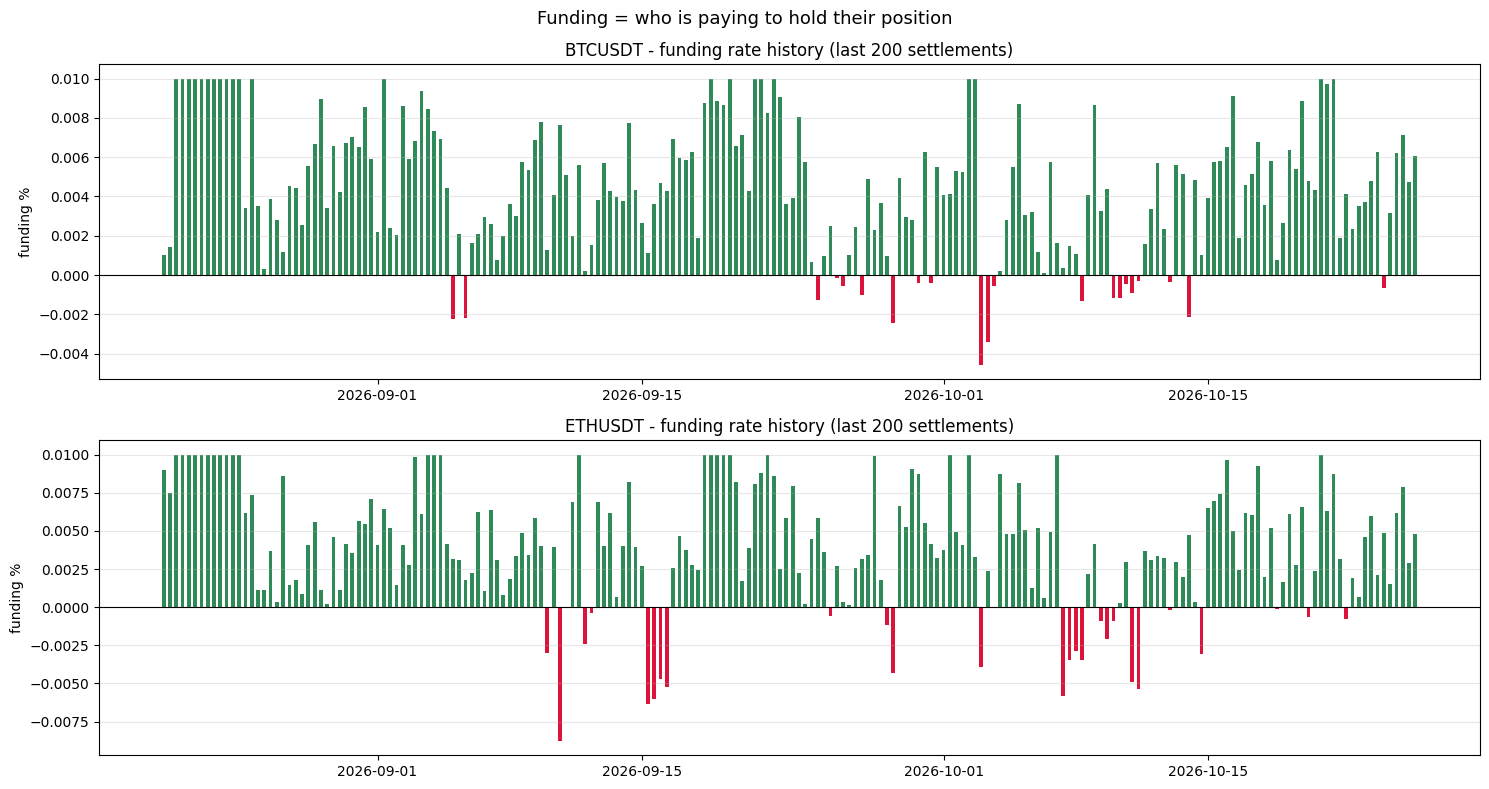


Funding statistics:

BTCUSDT:
  Mean          : +0.0045%
  Median        : +0.0043%
  Std           : 0.0034%
  Min           : -0.0046%
  Max           : +0.0100%
  % positive    : 89.5%
  % negative    : 10.5%

ETHUSDT:
  Mean          : +0.0040%
  Median        : +0.0040%
  Std           : 0.0041%
  Min           : -0.0088%
  Max           : +0.0100%
  % positive    : 86.5%
  % negative    : 13.5%


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8))
for ax, sym in zip(axes, SYMBOLS):
    if sym not in funding_hist: continue
    df = funding_hist[sym]
    colors = ['seagreen' if x > 0 else 'crimson' for x in df.rate]
    ax.bar(df.ts, df.rate, color=colors, width=0.2)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(f'{sym} - funding rate history (last {len(df)} settlements)')
    ax.set_ylabel('funding %')
    ax.grid(alpha=0.3, axis='y')
plt.suptitle('Funding = who is paying to hold their position', fontsize=13)
plt.tight_layout(); plt.show()

print('\nFunding statistics:')
for sym, df in funding_hist.items():
    print(f'\n{sym}:')
    print(f'  Mean          : {df.rate.mean():+.4f}%')
    print(f'  Median        : {df.rate.median():+.4f}%')
    print(f'  Std           : {df.rate.std():.4f}%')
    print(f'  Min           : {df.rate.min():+.4f}%')
    print(f'  Max           : {df.rate.max():+.4f}%')
    print(f'  % positive    : {(df.rate > 0).mean()*100:.1f}%')
    print(f'  % negative    : {(df.rate < 0).mean()*100:.1f}%')

## 3. Funding distribution

Are we in an extreme right now? Funding is mean-reverting, so extremes tend to revert.

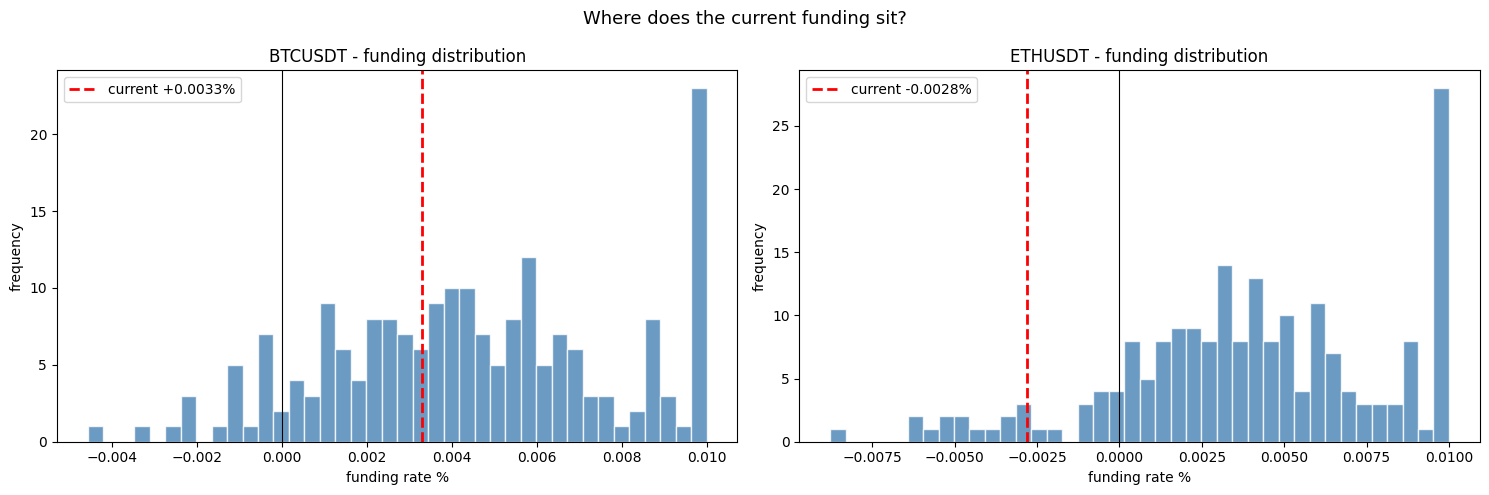


Current funding percentile:
  BTCUSDT: +0.0033% is at the 37th percentile
         -> Normal range
  ETHUSDT: -0.0028% is at the 8th percentile
         -> EXTREME LOW: crowded shorts, expect bounce


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, sym in zip(axes, SYMBOLS):
    if sym not in funding_hist: continue
    df = funding_hist[sym]
    ax.hist(df.rate, bins=40, color='steelblue', edgecolor='white', alpha=0.8)
    current = snapshots[sym]['funding'] if sym in snapshots else 0
    ax.axvline(current, color='red', lw=2, ls='--', label=f'current {current:+.4f}%')
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'{sym} - funding distribution')
    ax.set_xlabel('funding rate %')
    ax.set_ylabel('frequency')
    ax.legend()
plt.suptitle('Where does the current funding sit?', fontsize=13)
plt.tight_layout(); plt.show()

print('\nCurrent funding percentile:')
for sym, df in funding_hist.items():
    current = snapshots[sym]['funding'] if sym in snapshots else 0
    pct = (df.rate < current).mean() * 100
    print(f'  {sym}: {current:+.4f}% is at the {pct:.0f}th percentile')
    if pct > 90:
        print(f'         -> EXTREME HIGH: crowded longs, expect correction')
    elif pct < 10:
        print(f'         -> EXTREME LOW: crowded shorts, expect bounce')
    else:
        print(f'         -> Normal range')

## 4. Annualized carry

Positive funding means short perp + long spot earns carry. Negative means the reverse.

In [6]:
print('=' * 72)
print('ANNUALIZED CARRY OPPORTUNITY')
print('=' * 72)
for sym, df in funding_hist.items():
    avg_3d = df.rate.tail(9).mean() * 3 * 365
    avg_7d = df.rate.tail(21).mean() * 3 * 365
    avg_30d = df.rate.tail(90).mean() * 3 * 365
    current = snapshots[sym]['funding'] * 3 * 365 if sym in snapshots else 0
    print(f'\n{sym}:')
    print(f'  Current annualized: {current:+.2f}%')
    print(f'  3d avg annualized : {avg_3d:+.2f}%')
    print(f'  7d avg annualized : {avg_7d:+.2f}%')
    print(f'  30d avg annualized: {avg_30d:+.2f}%')
    if avg_7d > 15:
        print(f'  -> STRONG carry: short perp + long spot for {avg_7d:.1f}% annualized')
    elif avg_7d < -15:
        print(f'  -> STRONG reverse carry: long perp + short spot for {-avg_7d:.1f}% annualized')
    else:
        print(f'  -> Carry not worth the risk')

ANNUALIZED CARRY OPPORTUNITY

BTCUSDT:
  Current annualized: +3.61%
  3d avg annualized : +5.03%
  7d avg annualized : +5.88%
  30d avg annualized: +3.83%
  -> Carry not worth the risk

ETHUSDT:
  Current annualized: -3.08%
  3d avg annualized : +4.97%
  7d avg annualized : +4.59%
  30d avg annualized: +3.67%
  -> Carry not worth the risk


## 5. Funding vs price divergence

Price up + funding positive = healthy. Price up + funding negative = squeeze. Price down + funding positive = stubborn longs. Price down + funding negative = real downtrend.

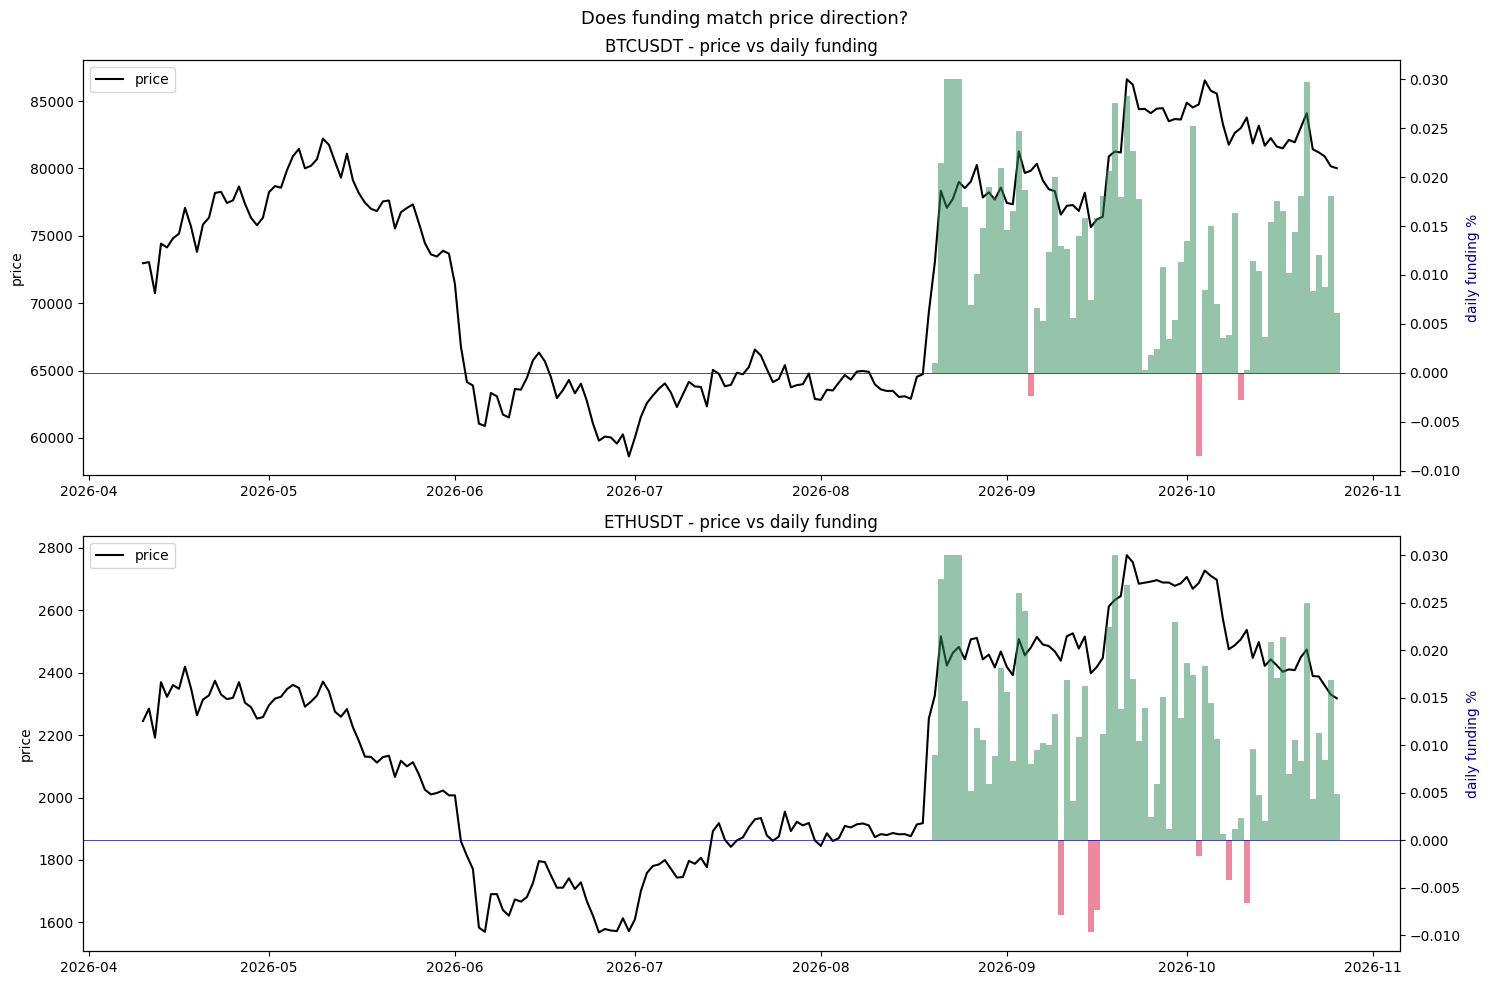

In [7]:
def fetch_klines(symbol, interval='1d', limit=200):
    r = requests.get(f'{BINANCE}/api/v3/klines',
                     params={'symbol': symbol, 'interval': interval, 'limit': limit},
                     timeout=15)
    r.raise_for_status()
    return r.json()

prices = {}
for sym in SYMBOLS:
    try:
        k = fetch_klines(sym, '1d', 200)
        rows = [{'date': pd.to_datetime(int(x[0]), unit='ms', utc=True).tz_convert(None),
                 'close': float(x[4])} for x in k]
        prices[sym] = pd.DataFrame(rows).set_index('date')
    except Exception as e:
        print(f'{sym}: {e}')

fig, axes = plt.subplots(2, 1, figsize=(15, 10))
for ax1, sym in zip(axes, SYMBOLS):
    if sym not in prices or sym not in funding_hist: continue
    df = funding_hist[sym].copy()
    df['date'] = df.ts.dt.date
    daily_funding = df.groupby('date')['rate'].sum().reset_index()
    daily_funding['date'] = pd.to_datetime(daily_funding.date)
    daily_funding = daily_funding.set_index('date')
    px = prices[sym].copy()
    px.index = pd.to_datetime(px.index.date)
    ax1.plot(px.index, px.close, color='black', lw=1.5, label='price')
    ax1.set_ylabel('price', color='black')
    ax1.set_title(f'{sym} - price vs daily funding')
    ax2 = ax1.twinx()
    colors = ['seagreen' if x > 0 else 'crimson' for x in daily_funding.rate]
    ax2.bar(daily_funding.index, daily_funding.rate, color=colors, alpha=0.5, width=1)
    ax2.set_ylabel('daily funding %', color='navy')
    ax2.axhline(0, color='navy', lw=0.5)
    ax1.legend(loc='upper left')
plt.suptitle('Does funding match price direction?', fontsize=13)
plt.tight_layout(); plt.show()

## 6. Extreme funding warnings

Above +0.05% or below -0.05% is historically unsustainable. A reversal usually follows within 24-48 hours.

In [8]:
print('=' * 72)
print('EXTREME FUNDING WARNINGS')
print('=' * 72)
for sym, s in snapshots.items():
    f = s['funding']
    print(f'\n{sym}:')
    if abs(f) > 0.05:
        print(f'  EXTREME: funding {f:+.4f}%')
        print(f'  Reversal risk is HIGH in next 24-48h')
        if f > 0.05:
            print(f'  Crowded longs. Expect a flush down.')
        else:
            print(f'  Crowded shorts. Expect a squeeze up.')
    elif abs(f) > 0.03:
        print(f'  ELEVATED: funding {f:+.4f}%')
        print(f'  Watch closely for reversal')
    else:
        print(f'  NORMAL: funding {f:+.4f}%')

EXTREME FUNDING WARNINGS

BTCUSDT:
  NORMAL: funding +0.0033%

ETHUSDT:
  NORMAL: funding -0.0028%


## 7. Signal interpretation

In [9]:
print('=' * 72)
print('FUNDING SIGNAL INTERPRETATION')
print('=' * 72)
for sym in SYMBOLS:
    if sym not in snapshots or sym not in prices: continue
    px = prices[sym].close
    price_chg_7d = (px.iloc[-1] / px.iloc[-8] - 1) * 100
    funding_avg_7d = funding_hist[sym].rate.tail(21).mean()
    print(f'\n{sym}:')
    print(f'  Price 7d change : {price_chg_7d:+.2f}%')
    print(f'  Funding 7d avg  : {funding_avg_7d:+.4f}%')
    if price_chg_7d > 0 and funding_avg_7d > 0.01:
        print(f'  HEALTHY UPTREND: new longs driving price up')
    elif price_chg_7d > 0 and funding_avg_7d < 0:
        print(f'  SHORT SQUEEZE: price up but shorts paying. Weak rally.')
    elif price_chg_7d < 0 and funding_avg_7d > 0.01:
        print(f'  STUBBORN LONGS: price down but longs paying. Flush likely.')
    elif price_chg_7d < 0 and funding_avg_7d < 0:
        print(f'  HEALTHY DOWNTREND: shorts driving price down')
    else:
        print(f'  NEUTRAL: no strong signal. Wait for clarity.')

FUNDING SIGNAL INTERPRETATION

BTCUSDT:
  Price 7d change : -2.35%
  Funding 7d avg  : +0.0054%
  NEUTRAL: no strong signal. Wait for clarity.

ETHUSDT:
  Price 7d change : -3.75%
  Funding 7d avg  : +0.0042%
  NEUTRAL: no strong signal. Wait for clarity.


## 8. Verdict

In [10]:
print('=' * 72)
print('FUNDING VERDICT')
print('=' * 72)
for sym in SYMBOLS:
    if sym not in snapshots: continue
    s = snapshots[sym]
    f = s['funding']
    ann = f * 3 * 365
    df = funding_hist[sym]
    pct = (df.rate < f).mean() * 100
    print(f'\n{sym}:  (mark ${s["mark"]:,.2f})')
    print(f'  Funding       : {f:+.4f}%  ({ann:+.1f}% annualized)')
    print(f'  Percentile    : {pct:.0f}th')
    if pct > 90:
        verdict = 'EXTREME GREED - crowded longs, expect flush'
        action = 'BUY PUTS or wait for a dump'
    elif pct < 10:
        verdict = 'EXTREME FEAR - crowded shorts, expect squeeze'
        action = 'BUY CALLS or wait for a pump'
    elif f > 0.02:
        verdict = 'ELEVATED POSITIVE - longs paying'
        action = 'Consider put protection or tighten stops'
    elif f < -0.02:
        verdict = 'ELEVATED NEGATIVE - shorts paying'
        action = 'Consider call exposure or fade shorts'
    else:
        verdict = 'NEUTRAL - no strong signal'
        action = 'Wait for clarity, use other signals'
    print(f'  VERDICT       : {verdict}')
    print(f'  ACTION        : {action}')

print()
print('=' * 72)
print('COMBINE WITH:')
print('=' * 72)
print('  pcr.ipynb             - options sentiment')
print('  oi_analysis.ipynb     - open interest positioning')
print('  greeks_analysis.ipynb - options Greeks')
print('Trade only when 2+ signals agree.')

FUNDING VERDICT

BTCUSDT:  (mark $79,965.92)
  Funding       : +0.0033%  (+3.6% annualized)
  Percentile    : 37th
  VERDICT       : NEUTRAL - no strong signal
  ACTION        : Wait for clarity, use other signals

ETHUSDT:  (mark $2,316.21)
  Funding       : -0.0028%  (-3.1% annualized)
  Percentile    : 8th
  VERDICT       : EXTREME FEAR - crowded shorts, expect squeeze
  ACTION        : BUY CALLS or wait for a pump

COMBINE WITH:
  pcr.ipynb             - options sentiment
  oi_analysis.ipynb     - open interest positioning
  greeks_analysis.ipynb - options Greeks
Trade only when 2+ signals agree.


## Notes

Funding settles every 8 hours: 00:00, 08:00, 16:00 UTC. In IST: 5:30 AM, 1:30 PM, 9:30 PM. Longs pay shorts when positive. Shorts pay longs when negative. Normal range is -0.02% to +0.02%. Extreme is above 0.05% or below -0.05%. Live from Bybit public API, no storage, no keys.